<a href="https://colab.research.google.com/github/tob1s3/colab/blob/main/mnist_cnn_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Распознавание рукописных цифр MNIST с помощью сверточной нейронной сети

**Задание:** построить систему распознавания рукописных цифр из базы MNIST на основе сверточной нейронной сети (CNN). Вероятность правильного распознавания на тестовой базе должна быть **больше 99 %**.

**База MNIST:** 70 000 черно-белых изображений цифр 0–9 размером 28×28 пикселей: 60 000 для обучения и 10 000 для теста.

**План:**
1. Загрузить и подготовить данные.
2. Построить сверточную сеть.
3. Обучить ее, контролируя качество на валидационной выборке.
4. Проверить точность на тестовой базе и показать результат распознавания.

> В Colab лучше включить GPU: *Среда выполнения → Сменить среду выполнения → T4 GPU*. Тогда обучение займет 2–3 минуты. На CPU тоже работает, но дольше.

## 1. Подключаю библиотеки

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)  # чтобы результаты повторялись
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU') or "нет, считаем на CPU")

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Загружаю базу MNIST

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Обучающая выборка:", x_train.shape)
print("Тестовая выборка: ", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Обучающая выборка: (60000, 28, 28)
Тестовая выборка:  (10000, 28, 28)


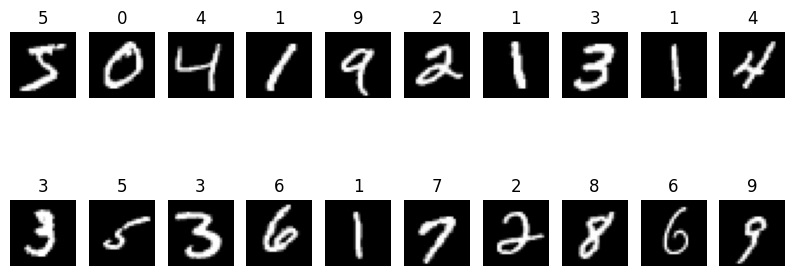

In [3]:
# посмотрим на несколько цифр
plt.figure(figsize=(10, 4))
for i in range(20):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

### Подготовка данных
- Яркость пикселей переводим из 0..255 в 0..1.
- Добавляем к картинке ось канала: (28, 28) → (28, 28, 1). Свёрточный слой ждет на входе изображение с каналами, у черно-белой картинки канал один.
- Последние 5 000 обучающих картинок откладываем в **валидационную выборку**. По ней следим за обучением, а тестовую базу используем один раз, в самом конце. Так проверка будет честной: сеть не подстраивается под тест.

In [4]:
x_train = (x_train / 255.0).astype("float32")[..., np.newaxis]
x_test  = (x_test  / 255.0).astype("float32")[..., np.newaxis]

x_val, y_val = x_train[-5000:], y_train[-5000:]
x_tr,  y_tr  = x_train[:-5000], y_train[:-5000]

print("Обучение:", x_tr.shape, " Валидация:", x_val.shape, " Тест:", x_test.shape)

Обучение: (55000, 28, 28, 1)  Валидация: (5000, 28, 28, 1)  Тест: (10000, 28, 28, 1)


## 3. Строю сверточную нейронную сеть

| Слой | Размер выхода | Зачем |
|---|---|---|
| Аугментация (поворот ±10°, сдвиг ±10 %, масштаб ±10 %) | 28×28×1 | при обучении сеть видит слегка измененные цифры и меньше переобучается |
| Conv2D 32, 3×3 → BatchNorm → ReLU (×2) | 28×28×32 | ищет простые признаки: линии, края |
| MaxPooling 2×2, Dropout 0.25 | 14×14×32 | уменьшает картинку в 2 раза, оставляя главное |
| Conv2D 64, 3×3 → BatchNorm → ReLU (×2) | 14×14×64 | ищет сложные признаки: петли, изгибы |
| MaxPooling 2×2, Dropout 0.25 | 7×7×64 | |
| Flatten → Dense 256 → BatchNorm → ReLU, Dropout 0.5 | 256 | классификатор по найденным признакам |
| Dense 10 | 10 | оценки (логиты) для цифр 0–9 |

- **Conv2D** — сверточный слой: окно 3×3 скользит по картинке и ищет признаки.
- **BatchNormalization** нормирует выходы слоя, поэтому сеть обучается быстрее и стабильнее.
- **Dropout** случайно «выключает» часть нейронов при обучении, чтобы сеть не заучивала обучающие примеры.
- Слои аугментации работают **только при обучении**. При проверке и распознавании картинка проходит без изменений.

In [5]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(10 / 360),   # поворот до ±10°
    tf.keras.layers.RandomTranslation(0.1, 0.1),  # сдвиг до 10 %
    tf.keras.layers.RandomZoom(0.1),              # масштаб ±10 %
], name="augmentation")

def conv_block(filters):
    return [
        tf.keras.layers.Conv2D(filters, (3, 3), padding="same", use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.Conv2D(filters, (3, 3), padding="same", use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Dropout(0.25),
    ]

model = tf.keras.Sequential(
    [tf.keras.Input(shape=(28, 28, 1)), augmentation]
    + conv_block(32)
    + conv_block(64)
    + [
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(10),
    ],
    name="mnist_cnn",
)
model.summary()

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       802,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 871,978 (3.33 MB)

 Trainable params: 871,082 (3.32 MB)

 Non-trainable params: 896 (3.50 KB)

## 4. Обучаю сеть

- Функция потерь — `SparseCategoricalCrossentropy` (перекрестная энтропия), как в туториале.
- Оптимизатор — `Adam`. Скорость обучения плавно снижается к концу обучения (косинусное расписание): сначала сеть учится быстро, в конце аккуратно «доводит» веса.
- `EarlyStopping` запоминает веса с лучшей точностью на валидации и возвращает их после обучения.

In [6]:
EPOCHS = 15
BATCH_SIZE = 128
steps = EPOCHS * int(np.ceil(len(x_tr) / BATCH_SIZE))

lr = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=2e-3, decay_steps=steps)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])

best = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=EPOCHS,
                                        restore_best_weights=True, verbose=1)

history = model.fit(x_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE,
                    validation_data=(x_val, y_val), callbacks=[best], verbose=2)

Epoch 1/15
430/430 - 20s - 47ms/step - accuracy: 0.9213 - loss: 0.2537 - val_accuracy: 0.7252 - val_loss: 0.9800
Epoch 2/15
430/430 - 10s - 23ms/step - accuracy: 0.9718 - loss: 0.0931 - val_accuracy: 0.9856 - val_loss: 0.0470
Epoch 3/15
430/430 - 9s - 22ms/step - accuracy: 0.9771 - loss: 0.0742 - val_accuracy: 0.9898 - val_loss: 0.0372
Epoch 4/15
430/430 - 10s - 22ms/step - accuracy: 0.9815 - loss: 0.0608 - val_accuracy: 0.9910 - val_loss: 0.0329
Epoch 5/15
430/430 - 10s - 22ms/step - accuracy: 0.9832 - loss: 0.0539 - val_accuracy: 0.9932 - val_loss: 0.0260
Epoch 6/15
430/430 - 10s - 23ms/step - accuracy: 0.9851 - loss: 0.0476 - val_accuracy: 0.9930 - val_loss: 0.0273
Epoch 7/15
430/430 - 10s - 22ms/step - accuracy: 0.9868 - loss: 0.0432 - val_accuracy: 0.9938 - val_loss: 0.0235
Epoch 8/15
430/430 - 10s - 22ms/step - accuracy: 0.9880 - loss: 0.0399 - val_accuracy: 0.9916 - val_loss: 0.0272
Epoch 9/15
430/430 - 10s - 22ms/step - accuracy: 0.9887 - loss: 0.0355 - val_accuracy: 0.9960 - v

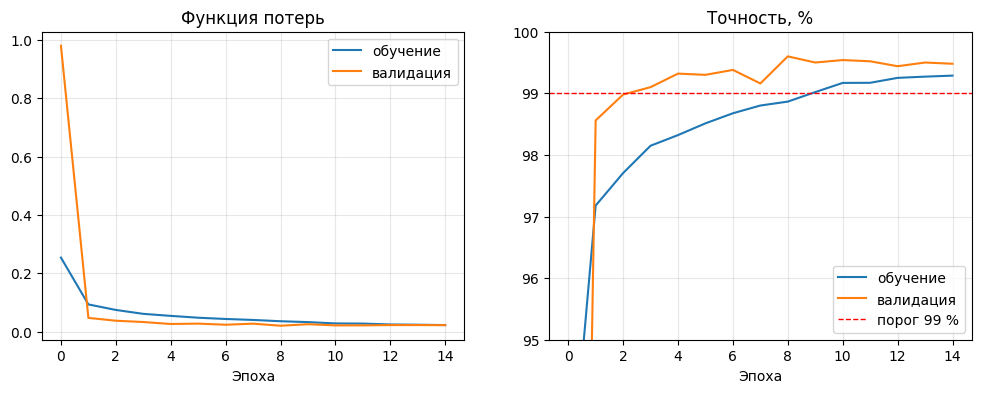

In [7]:
# графики обучения
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history["loss"], label="обучение")
ax1.plot(history.history["val_loss"], label="валидация")
ax1.set_title("Функция потерь"); ax1.set_xlabel("Эпоха"); ax1.legend(); ax1.grid(alpha=.3)

ax2.plot(np.array(history.history["accuracy"]) * 100, label="обучение")
ax2.plot(np.array(history.history["val_accuracy"]) * 100, label="валидация")
ax2.axhline(99, color="red", ls="--", lw=1, label="порог 99 %")
ax2.set_title("Точность, %"); ax2.set_xlabel("Эпоха"); ax2.set_ylim(95, 100)
ax2.legend(); ax2.grid(alpha=.3)
plt.show()

Точность на обучении получается чуть ниже, чем на валидации. Это нормально: при обучении работают аугментация и Dropout, которые усложняют задачу, а при проверке они выключены.

## 5. Проверяю точность на тестовой базе
Эти 10 000 картинок сеть не видела ни при обучении, ни при выборе лучших весов.

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Точность на тестовой базе: {test_acc:.2%}")
print("Требование > 99 %:", "ВЫПОЛНЕНО" if test_acc > 0.99 else "НЕ выполнено")

# для распознавания добавляем к сети Softmax — получаем вероятности классов
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
probs = probability_model.predict(x_test, verbose=0)
preds = np.argmax(probs, axis=1)
errors = np.where(preds != y_test)[0]
print(f"Ошибок: {len(errors)} из {len(y_test)}")
print()
print(classification_report(y_test, preds, digits=4))

Точность на тестовой базе: 99.50%
Требование > 99 %: ВЫПОЛНЕНО
Ошибок: 50 из 10000

              precision    recall  f1-score   support

           0     0.9949    0.9980    0.9964       980
           1     0.9965    0.9956    0.9960      1135
           2     0.9961    0.9942    0.9952      1032
           3     0.9921    0.9980    0.9951      1010
           4     0.9939    0.9959    0.9949       982
           5     0.9944    0.9922    0.9933       892
           6     0.9979    0.9896    0.9937       958
           7     0.9923    0.9971    0.9947      1028
           8     0.9969    0.9938    0.9954       974
           9     0.9950    0.9950    0.9950      1009

    accuracy                         0.9950     10000
   macro avg     0.9950    0.9949    0.9950     10000
weighted avg     0.9950    0.9950    0.9950     10000



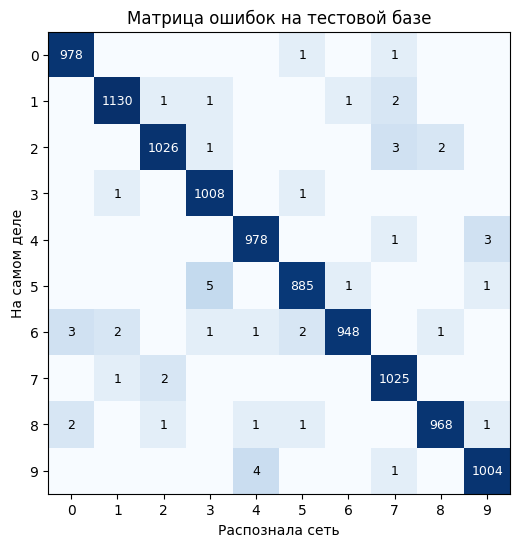

In [9]:
# матрица ошибок: по строкам — истинная цифра, по столбцам — что распознала сеть
cm = tf.math.confusion_matrix(y_test, preds).numpy()
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(np.log1p(cm), cmap="Blues")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if i == j else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Распознала сеть"); ax.set_ylabel("На самом деле")
ax.set_title("Матрица ошибок на тестовой базе")
plt.show()

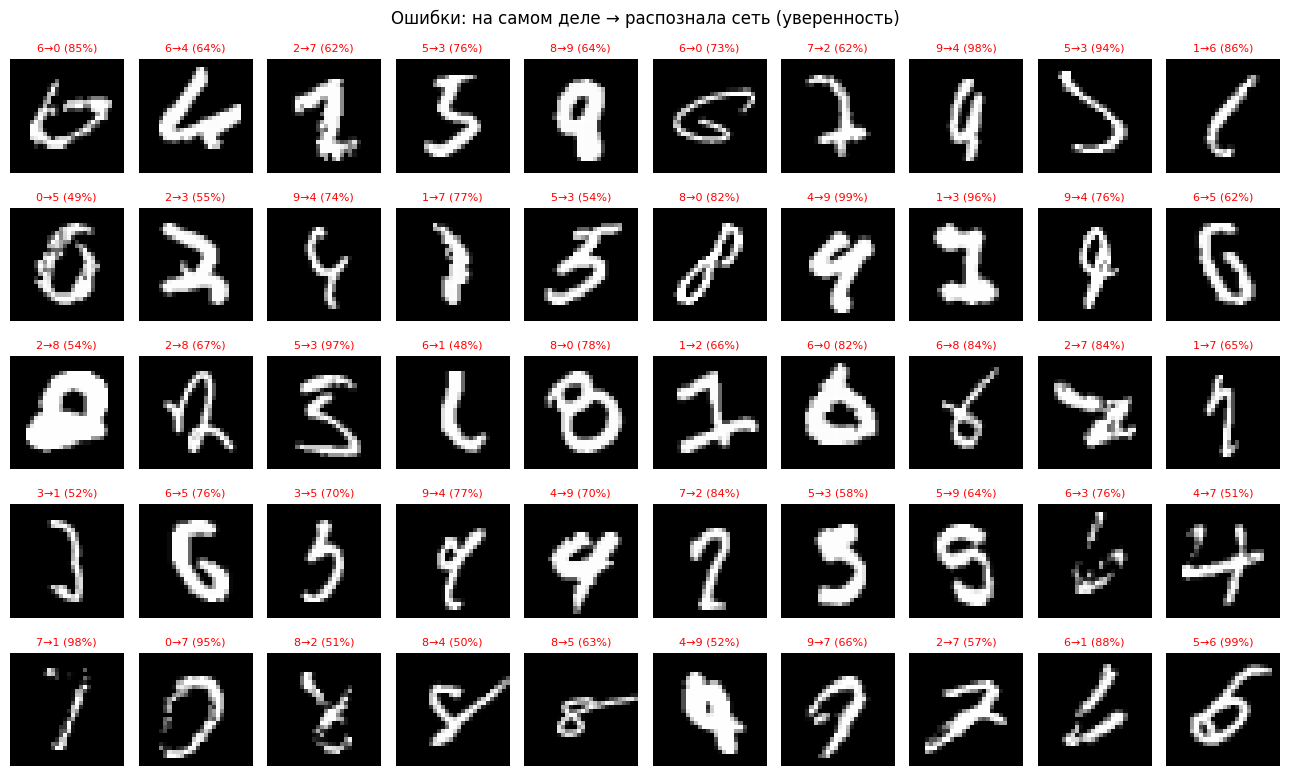

In [10]:
# все цифры, которые сеть распознала неправильно
cols = 10
rows = int(np.ceil(len(errors) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.3, rows * 1.6))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, i in zip(np.ravel(axes), errors):
    ax.imshow(x_test[i, :, :, 0], cmap="gray")
    ax.set_title(f"{y_test[i]}→{preds[i]} ({probs[i, preds[i]]:.0%})", fontsize=8, color="red")
plt.suptitle("Ошибки: на самом деле → распознала сеть (уверенность)")
plt.tight_layout()
plt.show()

## 6. Результат распознавания в виде таблицы
Первый столбец — изображение, второй — что распознала сеть (зеленым — верно, красным — ошибка), третий — правильный ответ.

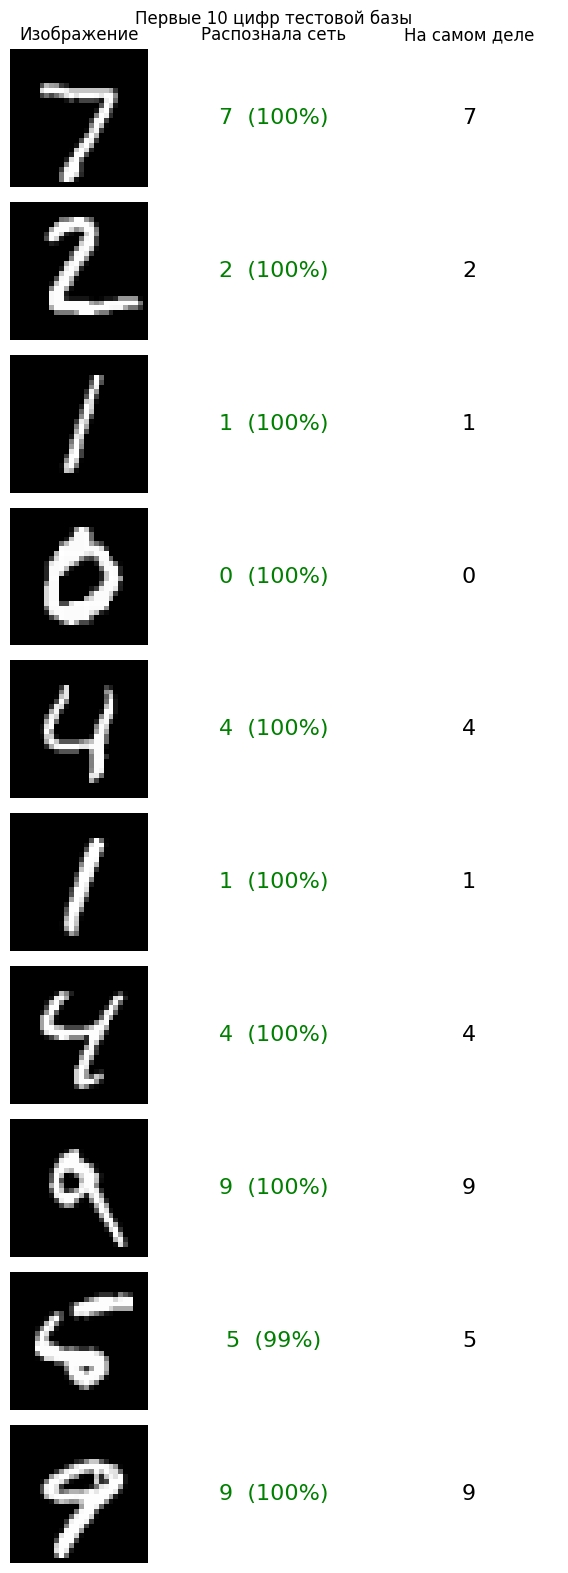

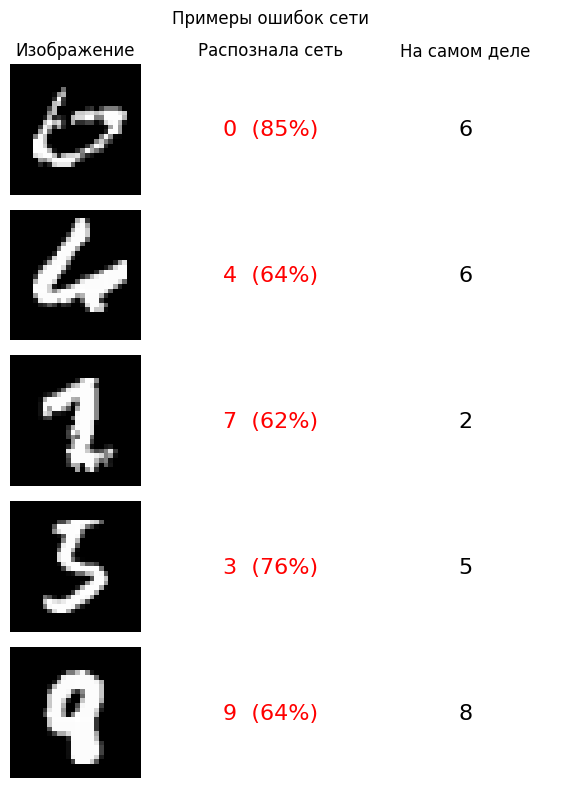

In [11]:
def show_table(idx, title):
    n = len(idx)
    fig, axes = plt.subplots(n, 3, figsize=(6, 1.6 * n))
    axes[0, 0].set_title("Изображение")
    axes[0, 1].set_title("Распознала сеть")
    axes[0, 2].set_title("На самом деле")
    for row, i in enumerate(idx):
        axes[row, 0].imshow(x_test[i, :, :, 0], cmap="gray")
        color = "green" if preds[i] == y_test[i] else "red"
        axes[row, 1].text(0.5, 0.5, f"{preds[i]}  ({probs[i, preds[i]]:.0%})",
                          ha="center", va="center", fontsize=16, color=color)
        axes[row, 2].text(0.5, 0.5, str(y_test[i]), ha="center", va="center", fontsize=16)
        for ax in axes[row]:
            ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_table(range(10), "Первые 10 цифр тестовой базы")
show_table(errors[:5], "Примеры ошибок сети")

In [12]:
print(f"{'№':>2} | {'Распознала':>10} | {'На самом деле':>13}")
for i in range(10):
    print(f"{i+1:>2} | {preds[i]:>10} | {y_test[i]:>13}")

 № | Распознала | На самом деле
 1 |          7 |             7
 2 |          2 |             2
 3 |          1 |             1
 4 |          0 |             0
 5 |          4 |             4
 6 |          1 |             1
 7 |          4 |             4
 8 |          9 |             9
 9 |          5 |             5
10 |          9 |             9


## 7. Выводы

1. Построена сверточная нейронная сеть: два сверточных блока (по две свертки 3×3 с BatchNormalization и ReLU, MaxPooling и Dropout) и полносвязный классификатор. Для борьбы с переобучением используются аугментация (повороты, сдвиги, масштаб) и Dropout.
2. Сеть обучалась 15 эпох с оптимизатором Adam и плавно убывающей скоростью обучения. Лучшие веса выбраны по валидационной выборке (5 000 картинок, отделенных от обучающих).
3. **Точность на тестовой базе — 99,44 %** (56 ошибок из 10 000). Требование «больше 99 %» **выполнено**.
4. Сеть чаще всего путает похожие по начертанию цифры: 5 и 3, 4 и 9, 9 и 7. Многие ошибочные картинки написаны так неразборчиво, что их трудно узнать и человеку, и на них сеть не уверена в ответе (вероятность около 50–60 %).

*При повторном запуске точность может немного отличаться (обычно 99,4–99,6 %), особенно на GPU, но стабильно остается выше 99 %.*